# Chapter 7 — Support Vector Machines and Kernel Methods
**Buku:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt, 2025)

**Ringkasan chapter.** *Support Vector Machine* (SVM) mencari **hyperplane dengan margin terbesar** antara kelas. Dengan **kernel trick**, SVM dapat memisahkan data yang tidak terpisah linear tanpa menghitung koordinat ruang berdimensi tinggi secara eksplisit. Chapter ini membahas SVM dasar (klasifikasi dan regresi), fungsi kernel, tuning parameter, SVM pada data berdimensi tinggi, dan evaluasi (termasuk ROC).

| # | Recipe | Dataset |
|---|---|---|
| 1 | Introduction to SVMs | Iris |
| 2 | Kernel functions and their applications | Iris |
| 3 | Tuning SVM parameters | Iris |
| 4 | SVMs in high-dimensional spaces | Sintetis (`make_classification`, 1000 fitur) |
| 5 | Evaluating SVM models | Breast Cancer |

> Bagian *Hands-on exercises* dan *Practical exercises* tidak dimasukkan. Penyesuaian kode buku dicatat di sel terkait.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score

def show_report(y_true, y_pred, target_names=None, **kw):
    """Classification report -> DataFrame berwarna (menggantikan blok styling yang diulang di buku)."""
    rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=target_names,
                                             output_dict=True, **kw)).transpose()
    return (rep.style
            .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
            .format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))

import sklearn
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


## 1. Introduction to SVMs

### Konsep
- **Hyperplane** adalah bidang pemisah antar kelas; pada ruang 2D berupa garis, pada 3D berupa bidang. **Margin** adalah jarak hyperplane ke titik terdekat dari tiap kelas; titik-titik terdekat itu disebut **support vectors**. SVM memilih hyperplane dengan **margin terbesar** agar kesalahan generalisasi kecil.
- Untuk hyperplane $w\cdot x + b = 0$, lebar margin adalah $\frac{2}{\lVert w\rVert}$, jadi memaksimalkan margin = meminimalkan $\lVert w\rVert$.
- **Soft margin:** data nyata jarang terpisah sempurna, sehingga SVM mentoleransi pelanggaran lewat *slack variables* $\xi_i$: $\ \min\ \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i$. Parameter **`C`** besar → toleransi kesalahan kecil (margin sempit, risiko overfitting); `C` kecil → margin lebar, lebih toleran.
- **Kernel** memetakan data ke ruang berdimensi lebih tinggi agar dapat dipisahkan hyperplane (dibahas di recipe 2).
- SVM efektif bila jumlah fitur besar dibanding jumlah sampel, dan tersedia untuk **klasifikasi (`SVC`)** serta **regresi (`SVR`)**. SVR memakai *tabung* $\varepsilon$: titik di dalam tabung tidak dikenai penalti.

> **Catatan koreksi:** kotak "What is a hyperplane?" di buku menyebut hyperplane sebagai "*non-linear line*". Secara definisi hyperplane itu **datar (linear)**, di ruang fitur asli untuk kernel linear atau di ruang fitur hasil kernel untuk kernel non-linear. Batas yang **tampak melengkung** pada ruang asli adalah proyeksi hyperplane datar dari ruang kernel.

### Kode

In [2]:
# [Buku] Getting ready: Iris, split 70/30
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


In [3]:
# [Buku] SVM klasifikasi, kernel linear
svm_classifier = SVC(kernel="linear")
svm_classifier.fit(X_train, y_train)
y_pred = svm_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Jumlah support vectors per kelas:", svm_classifier.n_support_)
show_report(y_test, y_pred)

Accuracy: 0.93
Jumlah support vectors per kelas: [ 3 10  8]


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [4]:
# [Buku] SVM regresi (SVR, kernel RBF) pada dua fitur pertama
from sklearn.metrics import mean_squared_error

svm_regressor = SVR(kernel="rbf")
svm_regressor.fit(X_train[:, :2], y_train)
y_pred_reg = svm_regressor.predict(X_test[:, :2])

mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")     # buku: 0.20

MSE: 0.20


### Hasil dan interpretasi
- SVM linear: akurasi **0,933** (buku: 93%). Kelas 0 sempurna; kesalahan ada pada kelas 1 dan 2. Hanya **21 dari 105** sampel latih menjadi *support vectors* (3, 10, dan 8 per kelas): hanya titik di dekat batas yang menentukan model.
- SVR: **MSE 0,20** (sama dengan buku). Label kelas (0/1/2) diperlakukan sebagai angka kontinu, sehingga MSE 0,20 berarti galat rata-rata ≈ 0,45 "unit kelas" ($\sqrt{0{,}20}$). Ini hanya demonstrasi API regresi.

### Visualizing SVM decision boundaries
> **Penyederhanaan kode:** buku membuat `meshgrid` dan kolom nol tambahan lalu memasukkannya ke `DecisionBoundaryDisplay.from_estimator`. Fungsi itu sudah membuat grid sendiri dari rentang `X`, jadi cukup diberi `X[:, :2]`; hasil gambarnya setara.

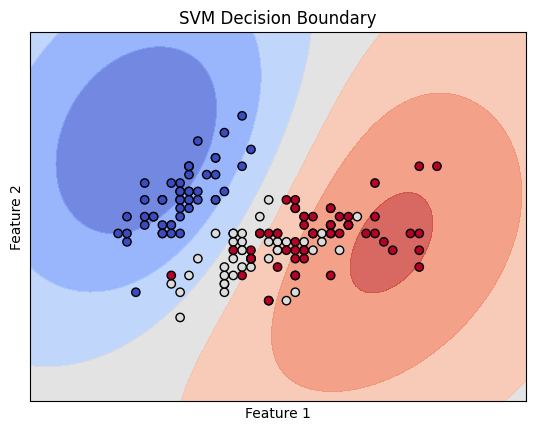

In [5]:
# [Buku, disederhanakan] Kontur prediksi SVR pada dua fitur pertama
from sklearn.inspection import DecisionBoundaryDisplay

fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor, X[:, :2], response_method="predict",
    plot_method="contourf", cmap=plt.cm.coolwarm, alpha=0.8, ax=ax)
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", marker="o", cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2")
ax.set_xticks(()); ax.set_yticks(())
plt.show()

**Interpretasi:** warna kontur adalah **nilai keluaran SVR** (angka kontinu antara sekitar 0 dan 2) pada tiap titik ruang dua fitur, sedangkan titik adalah data asli berwarna menurut kelas. Gambar ini bukan batas keputusan sebuah classifier dengan margin, melainkan permukaan prediksi sebuah **regresor** yang dilatih pada label kelas yang diperlakukan sebagai angka. Buku mengakui kegunaannya hanya sebagai ilustrasi; untuk klasifikasi sebenarnya gunakan `SVC`.

## 2. Kernel Functions and Their Applications

### Konsep
- **Kernel trick:** SVM hanya membutuhkan **hasil kali dalam** antar titik di ruang berdimensi tinggi, $K(x, z) = \phi(x)\cdot\phi(z)$, yang dapat dihitung langsung dari data asli tanpa pernah menghitung $\phi(x)$. Analogi buku: akordeon yang direntangkan menjadi 3D untuk menemukan batas, lalu dipipihkan kembali sehingga batas lurus tadi tampak melengkung.

| Kernel | Rumus $K(x,z)$ | Kapan dipakai |
|---|---|---|
| **Linear** | $x\cdot z$ | Data (hampir) terpisah linear, fitur banyak. *Tidak* memetakan ke dimensi lebih tinggi (pemetaan identitas) |
| **Polynomial** | $(\gamma\, x\cdot z + r)^d$ | Ada relasi polinomial antar fitur; derajat diatur `degree` |
| **RBF (Gaussian)** | $\exp(-\gamma\lVert x - z\rVert^2)$ | Pilihan umum untuk batas kompleks; memetakan ke ruang berdimensi tak hingga |
| **Sigmoid** | $\tanh(\gamma\, x\cdot z + r)$ | Kasus khusus (disebut di "There's more") |

- **`gamma`** mengatur seberapa jauh pengaruh satu sampel latih: `gamma` besar → pengaruh sempit, batas rumit (risiko overfitting); kecil → batas halus. Default scikit-learn `gamma="scale"`.
- Dalam *bahasa buku*, linear/polinomial/RBF "memetakan data ke ruang berdimensi lebih tinggi"; secara tepat itu berlaku untuk polinomial dan RBF, bukan untuk kernel linear.

### Kode

In [6]:
# [Buku] Kernel polinomial (degree = 3)
svm_poly = SVC(kernel="poly", degree=3)
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)
accuracy_poly = accuracy_score(y_test, y_pred_poly)
print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
show_report(y_test, y_pred_poly)

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


In [7]:
# [Buku] Kernel RBF (parameter default)
svm_rbf = SVC(kernel="rbf")
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
show_report(y_test, y_pred_rbf)

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


### Hasil dan interpretasi
- Akurasi pada data uji (45 sampel): **linear 0,933 → polinomial 0,956 → RBF 0,911**, sama dengan Figure 7.1, 7.3, dan 7.4.
- Selisih antar-kernel hanya **1–2 sampel uji** (43, 42, dan 41 benar dari 45). Kesimpulan buku bahwa data "kemungkinan berstruktur polinomial" dan RBF "terburuk" belum didukung secara statistik; RBF di sini juga memakai parameter default (`C=1`, `gamma="scale"`) yang belum dituning. Perbandingan yang andal memerlukan cross-validation.

### Visualizing kernel effects
Tiga model dilatih hanya dengan **dua fitur pertama** supaya batas keputusannya dapat digambar di 2D.

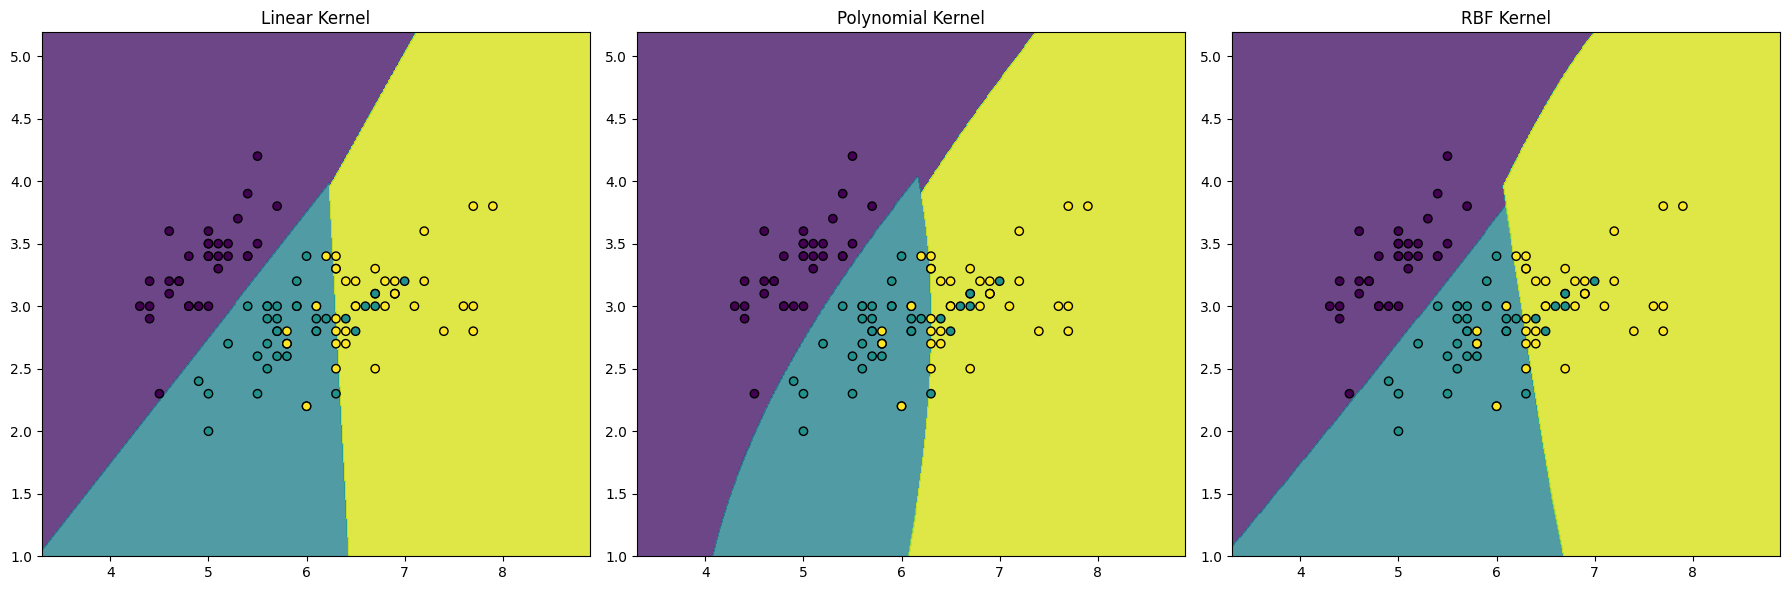

In [8]:
# [Buku] Batas keputusan tiga kernel pada dua fitur pertama
X_train_2d = X_train[:, :2]
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))
grid = np.c_[xx.ravel(), yy.ravel()]

svm_linear_2d = SVC(kernel="linear").fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel="poly").fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel="rbf").fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, mdl, name in zip(axes, [svm_linear_2d, svm_poly_2d, svm_rbf_2d],
                         ["Linear Kernel", "Polynomial Kernel", "RBF Kernel"]):
    Z = mdl.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.8)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors="k", marker="o")
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Interpretasi:** ketiga kernel menghasilkan wilayah keputusan yang mirip pada dua fitur ini, dengan perbedaan di bentuk batas antara kelas yang bertumpang tindih: batas kernel linear **lurus**, sedangkan polinomial dan RBF sedikit **melengkung**. Perbedaan kecil seperti ini bisa menentukan klasifikasi beberapa titik di perbatasan, tetapi pada data sekecil Iris belum tentu bermakna.

## 3. Tuning SVM Parameters

### Konsep
- **Grid search + cross-validation** menguji semua kombinasi hyperparameter; tiap kombinasi dinilai dengan $k$-fold CV, lalu kombinasi dengan skor rata-rata tertinggi dipilih. Waktu komputasi bertambah cepat seiring banyaknya parameter.
- **Parameter penting SVM:** `C` (trade-off margin vs kesalahan klasifikasi), `kernel`, serta parameter kernel (`degree` untuk polinomial, `gamma` untuk RBF/poli/sigmoid).
- Alternatifnya `RandomizedSearchCV`, yang mencoba sampel acak kombinasi (lebih hemat untuk ruang parameter besar).
- **Catatan grid:** `degree` hanya berpengaruh pada kernel `poly`, sehingga kombinasi `linear`/`rbf` dengan `degree` berbeda menghasilkan model yang sama. Grid 27 kombinasi di bawah efektifnya lebih sedikit.

### Kode

In [9]:
# [Buku] Grid search untuk SVC
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "degree": [2, 3, 4],
}
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")           # buku: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
print(f"Best Cross-Validation Score: {best_score:.2f}")   # buku: 0.99

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99


In [10]:
# [Buku] Latih ulang dengan parameter terbaik, evaluasi pada data uji
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
show_report(y_test, y_pred)

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


### Hasil dan interpretasi
- Grid search (27 kombinasi × 5 fold) memilih `{'C': 0.1, 'degree': 4, 'kernel': 'poly'}` dengan skor CV **0,99**, sama dengan buku.
- Akurasi data uji **0,933**, **sama persis** dengan SVM linear default di recipe 1 (report identik). Seperti kata buku, ini bukan kegagalan tuning, melainkan cerminan **mudahnya dataset**: banyak model berbeda sama-sama baik. Skor CV (0,99) juga dapat sedikit lebih optimistis daripada skor uji (0,933) karena merupakan yang terbaik dari banyak kombinasi, dan data uji hanya 45 sampel.

### Visualizing hyperparameter effects: pengaruh `C`

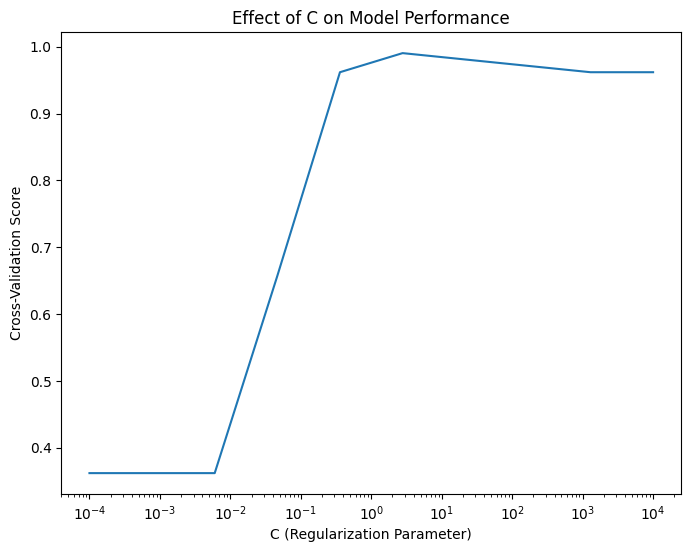

In [11]:
# [Buku] Pengaruh C pada kernel RBF
param_grid_c = {"C": np.logspace(-4, 4, 10), "kernel": ["rbf"]}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
plt.plot(grid_search_c.param_grid["C"], grid_search_c.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("C (Regularization Parameter)"); plt.ylabel("Cross-Validation Score")
plt.title("Effect of C on Model Performance")
plt.show()

**Cara membaca:** `C` terlalu kecil (≤ 0,006) membuat model terlalu longgar (*underfitting*): skor CV hanya 0,362, setara menebak acak untuk 3 kelas. Skor melonjak pada `C` ≈ 0,05–0,4 (0,657 → 0,962), mencapai **puncak 0,990 di `C` ≈ 2,8**, lalu turun perlahan (0,981 → 0,971 → 0,962 untuk `C` ≥ 1.291). Jadi menaikkan `C` melewati kisaran sekitar 1–10 tidak membantu dan sedikit merugikan (kecenderungan overfitting). Buku menyebut kurva mendatar di sekitar $C=10^1$, sejalan dengan hasil ini; perlu diingat kurva hanya terdiri dari 10 titik dan selisih puncak ke ujung kanan hanya sekitar 0,03.

## 4. SVMs in High-Dimensional Spaces

### Konsep
- Dataset **"wide"**: jumlah fitur besar dibanding jumlah sampel (misalnya mengukur kejadian langka dengan banyak sensor). SVM umumnya cocok karena kompleksitasnya ditentukan oleh margin dan *support vectors*, bukan langsung oleh jumlah dimensi.
- **Kernel linear** cocok untuk fitur sangat banyak; kernel non-linear (RBF/polinomial) untuk batas rumit.
- Pada dimensi tinggi, **regularisasi** (L1/L2, lewat `C`) penting untuk menekan pengaruh fitur tidak relevan dan mencegah overfitting.
- Memvisualisasikan data berdimensi tinggi memerlukan **reduksi dimensi** seperti **PCA** (dibahas di Chapter 3).

### Kode
`make_classification` membuat 1000 sampel dengan **1000 fitur**, hanya 50 yang informatif (950 sisanya *noise*).

In [12]:
# [Buku] Getting ready: dataset berdimensi tinggi
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (700, 1000) | Test: (300, 1000)


In [13]:
# [Buku] SVM linear pada 1000 fitur
svm_model = SVC(kernel="linear")
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")                                  # buku: 0.75
print(f"Akurasi pada data latih: {svm_model.score(X_train, y_train):.2f}")
show_report(y_test, y_pred)

Accuracy: 0.75
Akurasi pada data latih: 1.00


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


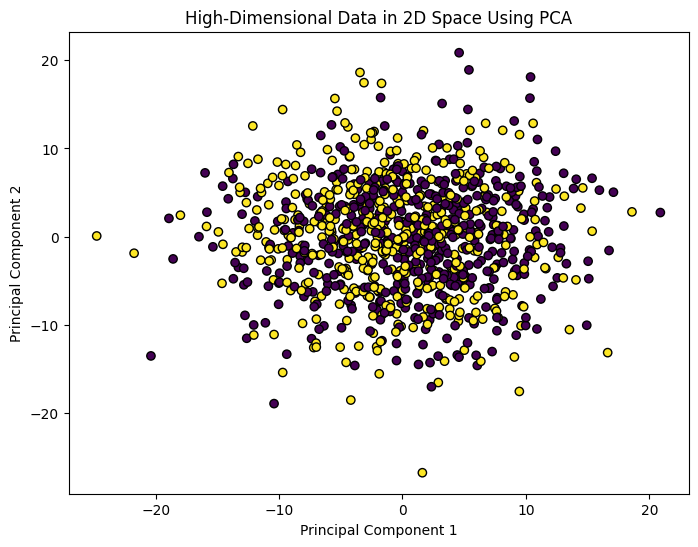

Variansi yang dijelaskan 2 komponen: 0.0457


In [14]:
# [Buku] Proyeksi PCA 2D untuk visualisasi
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors="k", marker="o")
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.show()
print("Variansi yang dijelaskan 2 komponen:", round(pca.explained_variance_ratio_.sum(), 4))

### Hasil dan interpretasi
- Akurasi uji **0,747** (sama dengan buku), tetapi akurasi pada **data latih = 1,00**. Selisih besar ini tanda **overfitting**. Dugaan penyebabnya: dengan 1000 fitur dan hanya 700 sampel latih, hyperplane linear dapat memisahkan data latih secara sempurna (fitur > sampel), sementara hanya 50 fitur yang informatif dan 950 sisanya *noise*. (Ini penjelasan teoretis yang konsisten dengan angka di atas, bukan hasil uji tersendiri.)
- PCA 2 komponen hanya menjelaskan **4,6% variansi**, sehingga proyeksi 2D tampak berantakan dengan kelas bercampur. Itu **tidak berarti data tidak terpisah**: SVM di ruang penuh mencapai 0,747 pada data uji (di atas ≈ 0,54 bila selalu menebak kelas mayoritas). PCA tidak memakai label dan memaksimalkan variansi, bukan keterpisahan kelas (bandingkan LDA di Chapter 3).
- Buku menyatakan "kita sudah tahu cara mengatasi masalah ini", tetapi recipe ini tidak menunjukkan solusinya. Arah yang masuk akal: regularisasi lebih kuat (`C` lebih kecil), seleksi fitur, atau penskalaan dan tuning kernel.

## 5. Evaluating SVM Models

### Konsep
- Metrik yang sama seperti Chapter 6: **accuracy, precision, recall, F1**, serta **kurva ROC dan AUC** (rumus dan cara baca ada di Chapter 6, recipe 5).
- `SVC` tidak menghasilkan probabilitas secara bawaan. Dengan **`probability=True`**, scikit-learn menjalankan kalibrasi probabilitas (*Platt scaling*) dengan **cross-validation internal 5-fold** sehingga pelatihan lebih lambat, dan `predict_proba` dapat sesekali tidak konsisten dengan `predict`. Alternatif untuk ROC adalah memakai skor mentah `decision_function` (jarak ke hyperplane), yang tidak butuh `probability=True`.
- Pemilihan metrik bergantung pada tujuan: precision bila *false positive* mahal, recall bila perlu menangkap sebanyak mungkin kasus positif.

> **Perbaikan kode:** di buku, recipe ini mencetak `accuracy` tanpa pernah menghitungnya dan tidak mengimpor `accuracy_score` (akan menghasilkan `NameError`). Keduanya ditambahkan.

### Kode

In [15]:
# [Buku] Getting ready: Breast Cancer, split 70/30
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import roc_curve, auc

data = load_breast_cancer()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (398, 30) | Test: (171, 30)


In [16]:
# [Buku] SVM linear dengan probabilitas
svm_model = SVC(kernel="linear", probability=True)
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)     # [perbaikan] tidak dihitung di buku
print(f"Accuracy: {accuracy:.2f}")
show_report(y_test, y_pred)

Accuracy: 0.95


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


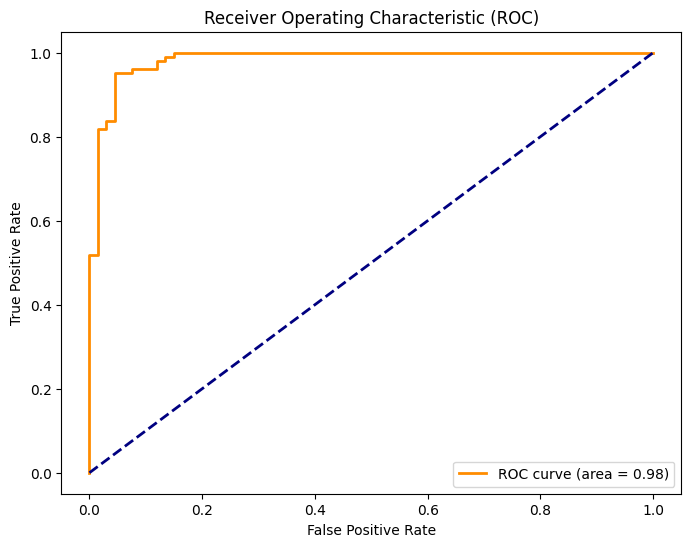

In [17]:
# [Buku] Kurva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()

### Hasil dan interpretasi
- Akurasi **0,947** (buku: 0,947). Kelas 1 (*benign*): precision 0,961 / recall 0,952; kelas 0 (*malignant*): precision 0,926 / recall 0,940 (Figure 7.10).
- **AUC ≈ 0,98** (0,984 pada eksekusi ini; buku: 0,98): kurva ROC naik cepat ke sudut kiri atas. Skor AUC yang sama (0,984) diperoleh bila memakai `decision_function` tanpa `probability=True`, jadi kalibrasi probabilitas tidak diperlukan hanya untuk menggambar ROC.
- Buku menyebut hasil ini lebih baik daripada recipe sebelumnya, tetapi sebagian karena **dataset-nya berbeda**: kelasnya lebih mudah dipisahkan dan masalahnya biner.

## Kesimpulan Chapter 7
- SVM mencari hyperplane dengan **margin maksimum**; *support vectors* adalah titik terdekat yang menentukan margin. **Soft margin** (`C`) menyeimbangkan lebar margin dan kesalahan.
- **Kernel trick** (linear, polinomial, RBF) menghitung hasil kali dalam di ruang berdimensi tinggi tanpa memetakan data secara eksplisit; `gamma` dan `degree` mengatur kompleksitas batas.
- **Tuning** `C`, `kernel`, dan parameter kernel dengan grid search + CV; pada data sederhana seperti Iris, hasil tuning mendekati default.
- Pada data **berdimensi tinggi** dengan banyak fitur tidak informatif, SVM default belum tentu optimal; regularisasi dan pemilihan fitur membantu.
- **Evaluasi:** classification report dan ROC-AUC; `probability=True` menambah biaya komputasi karena kalibrasi internal.